In [1]:
import os
print(os.getcwd())

D:\2026-2027\Python_Work\Kaggle


# 数据初步加载

In [2]:
import pandas as pd

# 备用链接1: Stanford 课程存档
url = "https://web.stanford.edu/class/archive/cs/cs109/cs109.1166/stuff/titanic.csv"
df = pd.read_csv(url)

# 如果上面的链接也失效了，可以试试备用链接2 (GitHub raw)
# url = "https://raw.githubusercontent.com/pandas-dev/pandas/master/doc/data/titanic.csv"
# df = pd.read_csv(url, index_col='Name')

# 打印所有的列名
print(df.columns.tolist())
# 输出格式为 (行数, 列数)
df.shape
# 查看列名、非空值数量以及数据类型（int, float, object等）
df.info()
df.head(2)
df.tail(2)



['Survived', 'Pclass', 'Name', 'Sex', 'Age', 'Siblings/Spouses Aboard', 'Parents/Children Aboard', 'Fare']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 887 entries, 0 to 886
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Survived                 887 non-null    int64  
 1   Pclass                   887 non-null    int64  
 2   Name                     887 non-null    object 
 3   Sex                      887 non-null    object 
 4   Age                      887 non-null    float64
 5   Siblings/Spouses Aboard  887 non-null    int64  
 6   Parents/Children Aboard  887 non-null    int64  
 7   Fare                     887 non-null    float64
dtypes: float64(2), int64(4), object(2)
memory usage: 55.6+ KB


,Survived,Pclass,Name,Sex,Age,Siblings/Spouses Aboard,Parents/Children Aboard,Fare
885,1,1,Mr. Karl Howell Behr,male,26.0,0,0,30.00
886,0,3,Mr. Patrick Dooley,male,32.0,0,0,7.75


# 性别与生存率

In [3]:
print('======性别与生存率==========')
print(df.groupby('Sex')['Survived'].mean())

======性别与生存率==========
Sex
female    0.742038
male      0.190227
Name: Survived, dtype: float64


# 随机查看

In [4]:
# print('====随机5名客人======')
df.sample(5)

,Survived,Pclass,Name,Sex,Age,Siblings/Spouses Aboard,Parents/Children Aboard,Fare
489,0,1,Mr. Harry Markland Molson,male,55.0,0,0,30.5000
639,0,3,Miss. Margit Elizabeth Skoog,female,2.0,3,2,27.9000
229,1,1,Mrs. Henry Birkhardt (Irene Wallach) Harris,female,35.0,1,0,83.4750
59,0,3,Mr. Orsen Sirayanian,male,22.0,0,0,7.2292
610,0,3,Mr. John Horgan,male,22.0,0,0,7.7500


# 年龄分布

In [5]:
print('======年龄分布==============')
print(df['Age'].describe())

======年龄分布==============
count    887.000000
mean      29.471443
std       14.121908
min        0.420000
25%       20.250000
50%       28.000000
75%       38.000000
max       80.000000
Name: Age, dtype: float64


In [6]:
print(df.describe(include=['object']))

                          Name   Sex
count                      887   887
unique                     887     2
top     Mr. Owen Harris Braund  male
freq                         1   573


# 从姓名提取头衔

Mr          513
Miss        182
Mrs         125
Master       40
Dr            7
Rev           6
Major         2
Mlle          2
Col           2
Don           1
Mme           1
Ms            1
Lady          1
Sir           1
Capt          1
Jonkheer      1
Name: Title, dtype: int64


D:\2026-2027\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 20056 (\N{CJK UNIFIED IDEOGRAPH-4E58}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
D:\2026-2027\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 23458 (\N{CJK UNIFIED IDEOGRAPH-5BA2}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
D:\2026-2027\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 31216 (\N{CJK UNIFIED IDEOGRAPH-79F0}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
D:\2026-2027\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 21628 (\N{CJK UNIFIED IDEOGRAPH-547C}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
D:\2026-2027\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


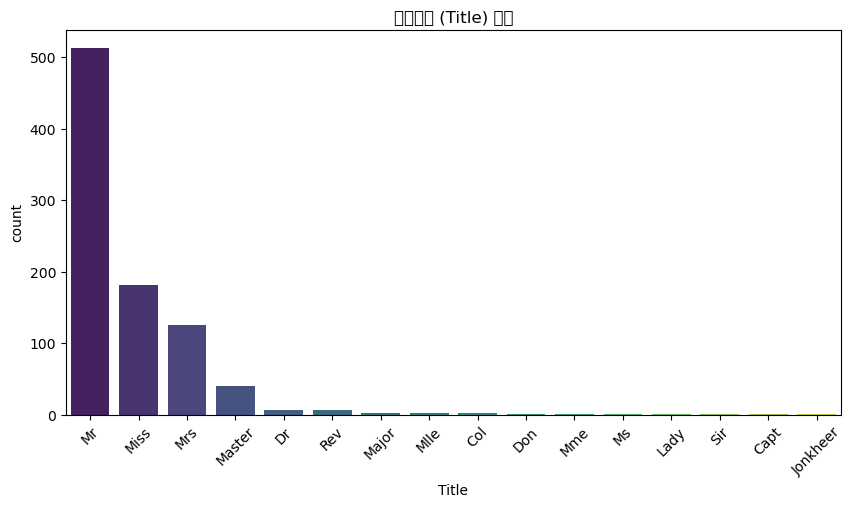

In [7]:
# 1. 修正正则：匹配开头首字母+点号
df['Title'] = df['Name'].str.extract(r'^([A-Za-z]+)\.', expand=False)

# 2. 看看现在提取出了哪些称呼，以及各自的频次
print(df['Title'].value_counts())

# 3. 把频次画成柱状图直观看看
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='Title', order=df['Title'].value_counts().index, palette='viridis')
plt.title('乘客称呼 (Title) 分布')
plt.xticks(rotation=45)
plt.show()

In [8]:
# 替换同义词
df['Title'] = df['Title'].replace(['Mlle', 'Ms'],'Miss')
df['Title'] = df['Title'].replace('Mme', 'Mrs')
#把出现次数极少的统称为Rare
rare_titles = ['Dr', 'Rev', 'Major', 'Col', 'Don', 'Lady', 'Sir', 'Capt', 'Jonkheer']
df['Title'] = df['Title'].replace(rare_titles, 'Rare')
#看看分布
print(df['Title'].value_counts())

Mr        513
Miss      185
Mrs       126
Master     40
Rare       22
Name: Title, dtype: int64


In [9]:
# 不同名称的生存率
title_survival = df.groupby('Title')['Survived'].mean().sort_values(ascending=False)
print(title_survival.map('{:.2%}'.format))

Title
Mrs       79.37%
Miss      70.27%
Master    57.50%
Rare      31.82%
Mr        15.79%
Name: Survived, dtype: object


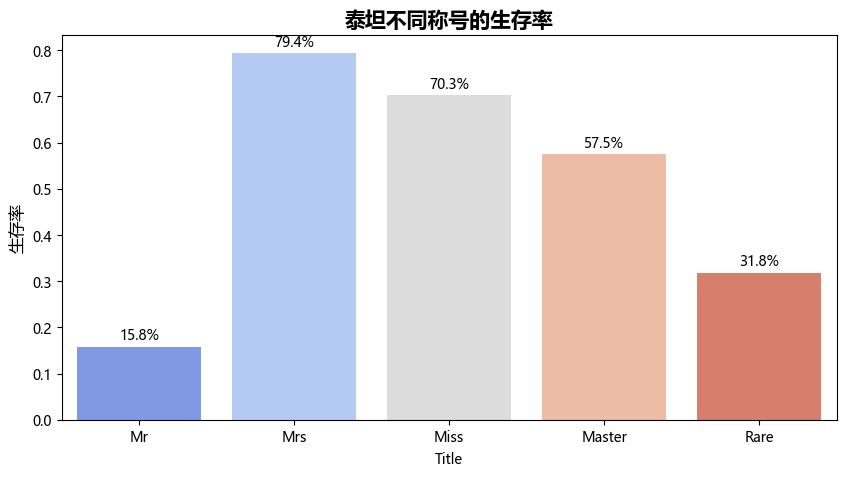

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
#字体
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Arial']
plt.rcParams['axes.unicode_minus'] = False  # 解决负号显示问题
plt.figure(figsize= (10,5))
sns.barplot(data=df, x='Title', y='Survived', palette='coolwarm', errorbar=None)
plt.title('泰坦不同称号的生存率', fontsize=15, fontweight='bold')
plt.ylabel('生存率', fontsize=12)
#标出百分比
for p in plt.gca().patches:
    plt.gca().annotate(f'{p.get_height():.1%}',
                      (p.get_x() + p.get_width() / 2, p.get_height()),
                      ha = 'center', va = 'center', xytext = (0, 8), textcoords = 'offset points')
plt.show()    

# 阶级与性别的生存率

In [11]:
# 仓位生存率
import pandas as pd
# 统计不同客舱等级，男女数量
sex_pclass = pd.crosstab(df['Pclass'], df['Sex'], margins=True, margins_name='等级')
print('\n===各等级客舱中男性的占比======')
print(df.groupby('Pclass')['Sex'].apply(lambda x: (x == 'male').mean()).map('{:.2%}'.format))



===各等级客舱中男性的占比======
Pclass
1    56.48%
2    58.70%
3    70.43%
Name: Sex, dtype: object


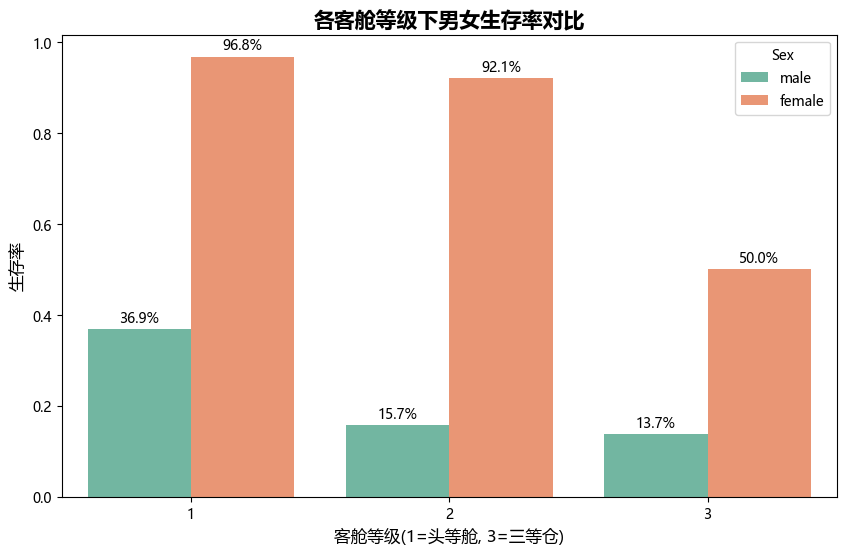

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Arial']
plt.rcParams['axes.unicode_minus'] = False  # 解决负号显示问题
plt.figure(figsize=(10,6))
sns.barplot(data=df, x='Pclass', y='Survived', hue='Sex', palette = 'Set2', errorbar=None)
plt.title('各客舱等级下男女生存率对比', fontsize=15, fontweight='bold')
plt.xlabel('客舱等级(1=头等舱, 3=三等仓)', fontsize=12)
plt.ylabel('生存率', fontsize=12)
#标出百分比
for p in plt.gca().patches:
    plt.gca().annotate(f'{p.get_height():.1%}',
                       (p.get_x() + p.get_width() / 2, p.get_height()),
                      ha = 'center', va = 'center', xytext = (0, 8), textcoords = 'offset points')
plt.show()